# PH 217 Project: Milankovitch Cycles and Ice Ages

**What this notebook does.** Earth's spin axis and orbit change slowly over tens of thousands of years, which changes how sunlight is spread over latitudes and seasons. We derive the periods of those changes from Newtonian mechanics and compare them with the ice-age record.

| Part | Question | Status |
|---|---|---|
| A | How fast does the spin axis precess under the torque of Sun and Moon? | derived, computed, verified against unaveraged integration |
| B | What are the slow frequencies of Earth's orbital eccentricity? | first-order (Laplace-Lagrange) done, compared with Laskar |
| C | Which planets are needed to get the ~100 and ~400 kyr terms? | tested |
| D | Climatic precession (19 to 23 kyr) | computed |
| E | Obliquity (41 kyr), insolation at 65°N, comparison with the LR04 δ¹⁸O record, the 100 kyr problem | done |

Optional extension: an N-body check of $e(t)$ to quantify the first-order error directly.

*AI statement for the report: AI was used for derivation outlines, code and checking. Every number below is produced by code in this notebook and each step must be explainable by the group.*

In [1]:
# Setup: installs any missing package into THIS kernel's Python, so the notebook runs on a fresh environment.
import importlib, subprocess, sys
for pkg in ("numpy", "scipy", "matplotlib"):
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from functools import lru_cache
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

ASEC_REV = 360*3600.0          # arcsec in one full turn
def kyr(rate_arcsec_per_yr):   # period in kyr for an angular rate in arcsec/yr
    return ASEC_REV/abs(rate_arcsec_per_yr)/1e3

## Part A: Precession of the spin axis

### A.1 Setup
Earth is an oblate spheroid with moments of inertia $C$ (about the spin axis) and $A$ (about an equatorial axis), with $C>A$. A distant mass $M$ at position $\mathbf r=r\hat{\mathbf r}$ gives a gravitational torque on this equatorial bulge (from the quadrupole term of the potential, $\hat{\mathbf s}$ is the spin axis direction):

$$\mathbf N = \frac{3GM}{r^3}\,(C-A)\,(\hat{\mathbf r}\cdot\hat{\mathbf s})\,(\hat{\mathbf r}\times\hat{\mathbf s}).$$

The torque is perpendicular to $\hat{\mathbf s}$, so it changes the **direction** of the spin angular momentum $\mathbf L = C\omega\,\hat{\mathbf s}$ and not its size:

$$\dot{\hat{\mathbf s}} = \frac{\mathbf N}{C\omega} = \frac{3GM}{\omega r^3}\,H\,(\hat{\mathbf r}\cdot\hat{\mathbf s})(\hat{\mathbf r}\times\hat{\mathbf s}),\qquad H=\frac{C-A}{C}.$$

### A.2 Orbit average
Take the ecliptic as the $xy$-plane and the Sun orbiting in it. Let the spin axis be $\hat{\mathbf s}=(\sin\varepsilon,0,\cos\varepsilon)$ at an instant ($\varepsilon$ is the obliquity). For a circular orbit $\hat{\mathbf r}=(\cos\theta,\sin\theta,0)$:

$$\hat{\mathbf r}\cdot\hat{\mathbf s}=\sin\varepsilon\cos\theta,\qquad \hat{\mathbf r}\times\hat{\mathbf s}=(\sin\theta\cos\varepsilon,\,-\cos\theta\cos\varepsilon,\,-\sin\theta\sin\varepsilon).$$

Averaging over $\theta$ ($\langle\cos^2\theta\rangle=\tfrac12$, $\langle\sin\theta\cos\theta\rangle=0$) leaves only the $y$-component:

$$\langle\dot s_y\rangle=-\frac{3GMH}{2\omega a^3}\sin\varepsilon\cos\varepsilon .$$

A motion of $\hat{\mathbf s}$ along $-y$ at fixed $\varepsilon$ is a **rotation about the ecliptic normal** with angular rate $\dot\psi=\langle\dot s_y\rangle/\sin\varepsilon$:

$$\boxed{\dot\psi=-\frac{3}{2}\,H\,\frac{GM}{a^3(1-e^2)^{3/2}}\,\frac{\cos\varepsilon}{\omega}}$$

(the minus sign means retrograde, like the observed precession of the equinoxes; the factor $(1-e^2)^{-3/2}$ is the eccentric-orbit average). The Moon gives the same form with $M\to M_\text{moon}$, $a\to a_\text{moon}$.

In [3]:
G = 6.67430e-11; Msun = 1.98841e30; Mmoon = 7.3459e22; AU = 1.495978707e11
a_moon = 3.844e8; e_earth = 0.0167; e_moon = 0.0549
eps = np.radians(23.439)                    # obliquity, J2000
omega = 2*np.pi/86164.0905                  # spin rate (sidereal day)
H = 0.0032737                               # dynamical ellipticity (C-A)/C
sec_per_yr = 365.25*86400

def prec_rate(M, a, e):                     # rad/s, negative = retrograde
    return -1.5*H*(G*M/(a**3*(1-e**2)**1.5))*np.cos(eps)/omega
to_as = lambda r: np.degrees(r*sec_per_yr)*3600

r_sun, r_moon = prec_rate(Msun, AU, e_earth), prec_rate(Mmoon, a_moon, e_moon)
p_total = to_as(r_sun + r_moon)
print(f"Sun   {to_as(r_sun):8.3f} arcsec/yr")
print(f"Moon  {to_as(r_moon):8.3f} arcsec/yr   (Moon/Sun = {r_moon/r_sun:.2f})")
print(f"Total {p_total:8.3f} arcsec/yr  ->  period {kyr(p_total):.1f} kyr")
print("Observed lunisolar precession ~ 50.4 arcsec/yr (~25.7 kyr); we are ~1% high.")

Sun    -15.949 arcsec/yr
Moon   -34.872 arcsec/yr   (Moon/Sun = 2.19)
Total  -50.820 arcsec/yr  ->  period 25.5 kyr
Observed lunisolar precession ~ 50.4 arcsec/yr (~25.7 kyr); we are ~1% high.


### A.3 Check: does orbit-averaging really work?
The averaged formula assumes the spin axis hardly moves during one year. We test that by integrating $\dot{\hat{\mathbf s}}$ with the **unaveraged** torque along a true Kepler ellipse (Sun only), for 3000 years, and fitting the precession rate. (We use the gyroscopic limit $L=C\omega$ fixed, which is exact for a fast spin; resolving every rotation would need ~$10^9$ steps for no extra insight.)

e=0.0000: unaveraged  -15.942  averaged  -15.942 arcsec/yr  (diff +0.0005%)


e=0.0167: unaveraged  -15.949  averaged  -15.949 arcsec/yr  (diff +0.0005%)


e=0.2000: unaveraged  -16.949  averaged  -16.949 arcsec/yr  (diff +0.0005%)


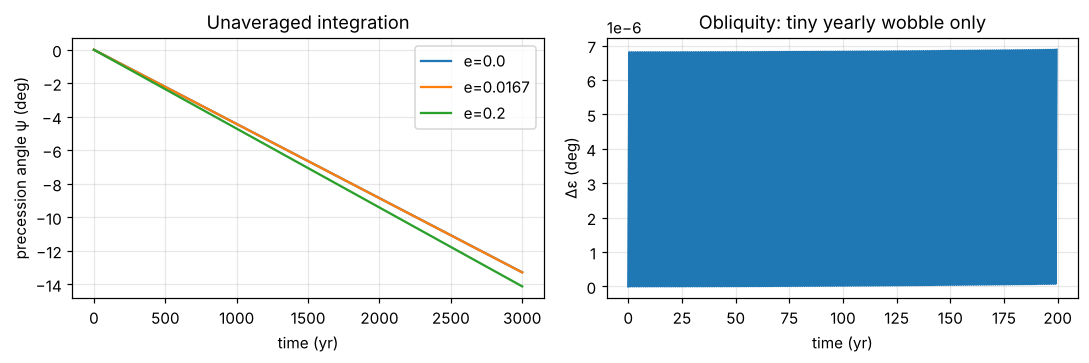

In [4]:
GM = 4*np.pi**2                    # AU^3/yr^2
omega_y = 2*np.pi*366.2564         # rad/yr
eps0 = np.radians(23.439)

def unaveraged(e, T=3000.0):
    n = 2*np.pi
    def rhat_r(t):
        M = n*t; E = M
        for _ in range(8): E -= (E - e*np.sin(E) - M)/(1 - e*np.cos(E))   # Kepler's equation
        r = 1 - e*np.cos(E)
        return np.array([np.cos(E)-e, np.sqrt(1-e*e)*np.sin(E), 0.0])/r, r
    def f(t, s):
        rh, r = rhat_r(t)
        return 3*GM*H/(omega_y*r**3)*(rh@s)*np.cross(rh, s)
    s0 = np.array([np.sin(eps0), 0, np.cos(eps0)])
    sol = solve_ivp(f, (0, T), s0, method="DOP853", rtol=1e-11, atol=1e-13, t_eval=np.linspace(0, T, 6001))
    psi = np.unwrap(np.arctan2(sol.y[1], sol.y[0]))
    obl = np.degrees(np.arccos(sol.y[2]))
    rate = np.degrees(np.polyfit(sol.t, psi, 1)[0])*3600
    avg = np.degrees(-1.5*H*GM/(1-e*e)**1.5/omega_y*np.cos(eps0))*3600
    return sol.t, psi, obl, rate, avg

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for e in (0.0, 0.0167, 0.2):
    t, psi, obl, rate, avg = unaveraged(e)
    print(f"e={e:6.4f}: unaveraged {rate:8.3f}  averaged {avg:8.3f} arcsec/yr  (diff {100*(rate-avg)/avg:+.4f}%)")
    ax[0].plot(t, np.degrees(psi), label=f"e={e}")
ax[0].set(xlabel="time (yr)", ylabel="precession angle ψ (deg)", title="Unaveraged integration"); ax[0].legend()
t, psi, obl, *_ = unaveraged(0.0167)
ax[1].plot(t[:400], obl[:400]-obl[0]); ax[1].set(xlabel="time (yr)", ylabel="Δε (deg)", title="Obliquity: tiny yearly wobble only")
plt.tight_layout(); plt.show()

**Result.** The unaveraged and averaged precession rates agree to ~$10^{-3}$ %, and the yearly wobble of the obliquity is ~$10^{-5}$ deg. Averaging is justified for the precession. The 1% gap to the observed 50.4″/yr is **not** from averaging; candidates are the tilt of the lunar orbit and the small planetary correction.

## Part B: Secular eccentricity (Laplace-Lagrange)

### B.1 Idea
Planets tug on each other's orbits [1]. Averaging the disturbing function over the fast mean longitudes leaves the slow evolution of $h_j=e_j\sin\varpi_j$, $k_j=e_j\cos\varpi_j$ ($\varpi$ = longitude of perihelion). To first order in the masses and eccentricities it is **linear**:

$$\frac{d\mathbf z}{dt}=+i\,\mathsf A\,\mathbf z,\qquad z_j=k_j+ih_j=e_je^{i\varpi_j},$$

$$A_{jj}=\frac{n_j}{4}\sum_{k\ne j}\frac{m_k}{M_\odot+m_j}\,\alpha_{jk}\bar\alpha_{jk}\,b^{(1)}_{3/2}(\alpha_{jk}),\qquad A_{jk}=-\frac{n_j}{4}\frac{m_k}{M_\odot+m_j}\,\alpha_{jk}\bar\alpha_{jk}\,b^{(2)}_{3/2}(\alpha_{jk}),$$

with $\alpha_{jk}=\min(a_j,a_k)/\max(a_j,a_k)$, $\bar\alpha_{jk}=\alpha_{jk}$ if planet $j$ is the inner one and $1$ otherwise, and the Laplace coefficients

$$b^{(j)}_{s}(\alpha)=\frac1\pi\int_0^{2\pi}\frac{\cos j\psi}{(1-2\alpha\cos\psi+\alpha^2)^{s}}\,d\psi .$$

Eigenvalues $g_i$ of $\mathsf A$ are the secular frequencies (positive: perihelia advance). Earth's $e(t)=|z_\oplus(t)|$ is a sum of modes with frequencies $g_i$, so $e^2$ (and hence insolation) varies at the **differences** $g_i-g_j$.

In [5]:
names = ["Mercury","Venus","Earth","Mars","Jupiter","Saturn","Uranus","Neptune"]
a  = np.array([0.38710, 0.72333, 1.00000, 1.52368, 5.20336, 9.53707, 19.1913, 30.0690])      # AU
m  = np.array([1.6601e-7, 2.4478e-6, 3.0404e-6, 3.2271e-7, 9.5479e-4, 2.8589e-4, 4.3662e-5, 5.1514e-5])  # Msun (Earth = Earth+Moon)
e0 = np.array([0.20563, 0.00677, 0.01671, 0.09341, 0.04839, 0.05415, 0.04717, 0.00859])      # J2000
pi0 = np.radians([77.46, 131.53, 102.94, 336.04, 14.75, 92.43, 170.96, 44.97])

@lru_cache(maxsize=None)
def laplace_b(s, j, al):
    return quad(lambda p: np.cos(j*p)/(1-2*al*np.cos(p)+al*al)**s, 0, 2*np.pi, limit=200)[0]/np.pi

def secular(idx):
    '''Laplace-Lagrange for the planets with indices idx. Returns g (arcsec/yr, sorted), Earth's mode weights, eigvecs, coefs.'''
    aa, mm = a[idx], m[idx]; n = ASEC_REV/aa**1.5; N = len(idx)
    A = np.zeros((N, N))
    for j in range(N):
        for k in range(N):
            if j == k: continue
            al, alb = (aa[j]/aa[k],)*2 if aa[j] < aa[k] else (aa[k]/aa[j], 1.0)
            c = 0.25*n[j]*mm[k]/(1+mm[j])*al*alb
            A[j, j] += c*laplace_b(1.5, 1, al); A[j, k] = -c*laplace_b(1.5, 2, al)
    g, V = np.linalg.eig(A); o = np.argsort(g.real); g, V = g.real[o], V.real[:, o]
    z0 = e0[idx]*np.cos(pi0[idx]) + 1j*e0[idx]*np.sin(pi0[idx])
    return g, V, np.linalg.solve(V, z0)

def earth_e(idx, t):
    g, V, coef = secular(idx); ie = list(idx).index(2)
    z = sum(V[ie, i]*coef[i]*np.exp(+1j*np.radians(g[i]/3600)*t) for i in range(len(idx)))
    return np.abs(z)

g_all, V_all, coef_all = secular(np.arange(8))
# physical labels of the sorted modes (verified below against the textbook table)
labels = ["g8","g7","g5","g1","g2","g3","g4","g6"]
textbook_LL = dict(g1=5.462, g2=7.346, g3=17.33, g4=18.00, g5=3.724, g6=22.44, g7=2.708, g8=0.6345)   # Brouwer & van Woerkom / Murray & Dermott
laskar_2011 = dict(g1=5.59,  g2=7.453, g3=17.368, g4=17.916, g5=4.2575, g6=28.245, g7=3.0879, g8=0.6730)  # full N-body fit (La2010)
for lab, gi in zip(labels, g_all):
    assert abs(gi - textbook_LL[lab]) < 0.1, (lab, gi)    # reproduces the textbook first-order table
print("mode   ours   textbook-LL   Laskar   error vs Laskar")
for lab in sorted(labels):
    gi = g_all[labels.index(lab)]
    print(f" {lab}   {gi:6.3f}   {textbook_LL[lab]:7.3f}     {laskar_2011[lab]:7.3f}    {100*(gi-laskar_2011[lab])/laskar_2011[lab]:+6.1f}%")

mode   ours   textbook-LL   Laskar   error vs Laskar
 g1    5.461     5.462       5.590      -2.3%
 g2    7.345     7.346       7.453      -1.4%
 g3   17.329    17.330      17.368      -0.2%
 g4   18.002    18.000      17.916      +0.5%
 g5    3.730     3.724       4.258     -12.4%
 g6   22.510    22.440      28.245     -20.3%
 g7    2.707     2.708       3.088     -12.3%
 g8    0.635     0.634       0.673      -5.7%


Our eigenfrequencies reproduce the textbook Laplace-Lagrange table [2, 3]. They differ from the accurate values [4] for $g_5$ ($-12\%$) and $g_6$ ($-20\%$): the Jupiter-Saturn pair sits near the 5:2 resonance (the "Great Inequality"), where first-order theory is poor [5]. This is a known limitation.

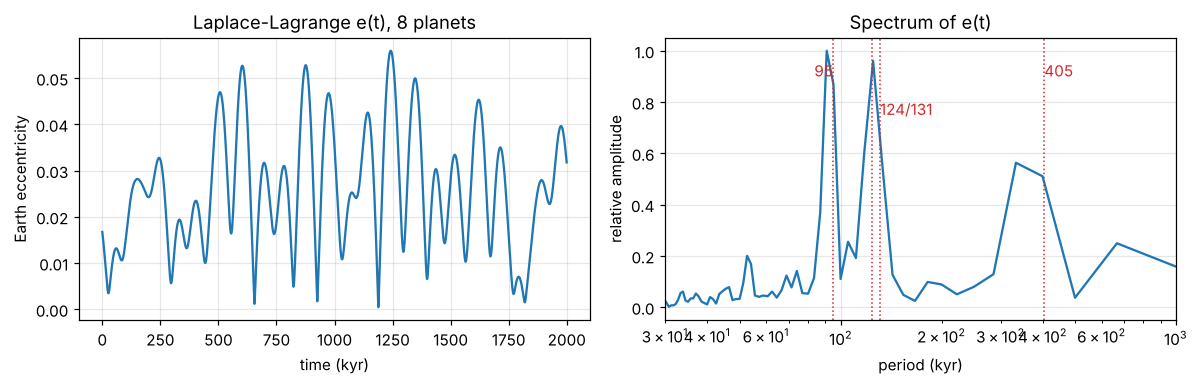

e range: 0.0004 to 0.0559 | spectral peaks (kyr): [91, 125, 333, 105, 667]


In [6]:
t = np.arange(0, 2.0e6, 500.0)                       # 2 Myr, 500 yr step
e_t = earth_e(np.arange(8), t)
sig = e_t - e_t.mean(); F = np.abs(np.fft.rfft(sig*np.hanning(len(sig)))); fr = np.fft.rfftfreq(len(sig), 500.0)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t/1e3, e_t); ax[0].set(xlabel="time (kyr)", ylabel="Earth eccentricity", title="Laplace-Lagrange e(t), 8 planets")
per = 1/fr[1:]/1e3
ax[1].plot(per, F[1:]/F.max()); ax[1].set(xscale="log", xlim=(30, 1000), xlabel="period (kyr)", ylabel="relative amplitude", title="Spectrum of e(t)")
for p in (95, 124, 131, 405): ax[1].axvline(p, color="C3", ls=":", lw=1)
ax[1].text(405, .9, "405", color="C3"); ax[1].text(95, .9, "95", color="C3", ha="right"); ax[1].text(131, .75, "124/131", color="C3")
plt.tight_layout(); plt.show()
pk = sorted([i for i in range(2, len(F)-1) if F[i] > F[i-1] and F[i] > F[i+1] and F[i] > .1*F.max()], key=lambda i: -F[i])[:5]
print("e range: %.4f to %.4f" % (e_t.min(), e_t.max()), "| spectral peaks (kyr):", [round(1/fr[i]/1e3) for i in pk])

### B.2 Beat periods: first-order vs accurate frequencies
Earth's eccentricity amplitudes are dominated by $g_2,g_3,g_4,g_5$. The periods of $e$ come from their differences.

In [7]:
pairs = [("g2","g5","405 kyr term"), ("g4","g5","~95 kyr"), ("g3","g5","~99 kyr"), ("g4","g2","~124 kyr"), ("g3","g2","~131 kyr")]
print("beat    ours (kyr)   with Laskar g (kyr)   note")
for x, y, note in pairs:
    ours = kyr(g_all[labels.index(x)] - g_all[labels.index(y)])
    lask = kyr(laskar_2011[x] - laskar_2011[y])
    print(f"{x}-{y}   {ours:8.1f}      {lask:8.1f}            {note}")

beat    ours (kyr)   with Laskar g (kyr)   note
g2-g5      358.5         405.6            405 kyr term
g4-g5       90.8          94.9            ~95 kyr
g3-g5       95.3          98.9            ~99 kyr
g4-g2      121.6         123.9            ~124 kyr
g3-g2      129.8         130.7            ~131 kyr


The 405 kyr term involves $g_5$ (Jupiter), which is where first-order theory is weakest, so we get ~358 kyr instead of ~405 kyr. The ~95-130 kyr group comes out within about 4 %. The *structure* (a 400 kyr term and a cluster near 100 kyr) is reproduced; the *Jupiter-linked* periods are not.

## Part C: How many planets do we need?
A "minimal" version using only Earth and Jupiter is tempting. We test it.

Earth + Jupiter                  peaks (kyr): [182, 91]
Earth + Jupiter + Saturn         peaks (kyr): [333, 167]
Venus, Earth, Jupiter, Saturn    peaks (kyr): [400, 95, 125, 69, 182]
all 8 planets                    peaks (kyr): [91, 125, 333, 105, 667]


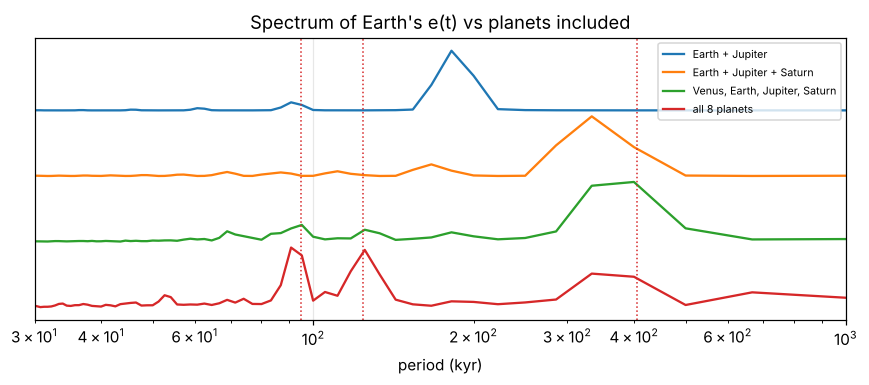

In [8]:
sets = {"Earth + Jupiter": [2,4], "Earth + Jupiter + Saturn": [2,4,5], "Venus, Earth, Jupiter, Saturn": [1,2,4,5], "all 8 planets": list(range(8))}
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (name, idx) in enumerate(sets.items()):
    idx = np.array(idx); e = earth_e(idx, t); s = e - e.mean()
    Fs = np.abs(np.fft.rfft(s*np.hanning(len(s)))); ax.plot(1/fr[1:]/1e3, Fs[1:]/Fs.max() + 1.1*(len(sets)-1-k), label=name)
    pk = sorted([i for i in range(2, len(Fs)-1) if Fs[i] > Fs[i-1] and Fs[i] > Fs[i+1] and Fs[i] > .1*Fs.max()], key=lambda i: -Fs[i])[:5]
    print(f"{name:32s} peaks (kyr): {[round(1/fr[i]/1e3) for i in pk]}")
for p in (95, 124, 405): ax.axvline(p, color="C3", ls=":", lw=1)
ax.set(xscale="log", xlim=(30, 1000), xlabel="period (kyr)", yticks=[], title="Spectrum of Earth's e(t) vs planets included"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

Earth + Jupiter alone gives only ~182 and ~91 kyr and **no 400 kyr term**. The 400 kyr beat appears to need Venus (it enters the $g_2$ mode), and Saturn shifts the Jupiter mode. **Venus + Earth + Jupiter + Saturn** is the smallest set that recovers both the ~400 kyr and the ~95-125 kyr terms. So the "Earth and Jupiter only" minimal option does not work; use at least four planets.

## Part D: Climatic precession (19 to 23 kyr)
The spin axis precesses retrograde at $p\approx50.4''$/yr, while the perihelion advances at rate $g$. Seasons relative to perihelion repeat at the combined rate $p+g$. This is the classic point of confusion: **26 kyr is the spin precession, 19 to 23 kyr is the climatic precession**.

In [9]:
p_obs = 50.4
print("perihelion rate g (arcsec/yr)   climatic precession period (kyr)")
for lab in ("g5", "g2", "g1", "g3", "g4"):
    gg = laskar_2011[lab]; print(f"   {lab}  {gg:7.3f}                      {kyr(p_obs+gg):6.1f}")
print("spin precession alone:", round(kyr(p_obs), 1), "kyr")

perihelion rate g (arcsec/yr)   climatic precession period (kyr)
   g5    4.258                        23.7
   g2    7.453                        22.4
   g1    5.590                        23.1
   g3   17.368                        19.1
   g4   17.916                        19.0
spin precession alone: 25.7 kyr


These land on the observed ~23.7, 22.4, 19.2, 19.0 kyr peaks of the climatic-precession band [6, 7].

## Part E: Obliquity, insolation and the ice record

### E.1 Obliquity (41 kyr)
Part A treated the orbital plane as fixed. It is not: the other planets make the orbit normal $\hat{\mathbf n}$ precess slowly. The spin axis keeps precessing about the *instantaneous* $\hat{\mathbf n}$, so the angle between them, the obliquity $\varepsilon$, changes.

**Spin axis.** The averaged torque of Part A in vector form is

$$\dot{\hat{\mathbf s}}=-\alpha\,(\hat{\mathbf n}\cdot\hat{\mathbf s})\,(\hat{\mathbf n}\times\hat{\mathbf s}),\qquad \alpha\simeq\frac{50.4''/\text{yr}}{\cos\varepsilon_0}=54.9''/\text{yr},$$

with $\alpha$ calibrated to the observed precession rate (tidal and ellipticity changes over Myr are ignored). Taking $\hat{\mathbf n}=\hat{\mathbf z}$ and $\hat{\mathbf s}=(\sin\varepsilon,0,\cos\varepsilon)$ gives back $\dot\psi=-\alpha\cos\varepsilon$.

**Orbit normal.** The inclination analogue of Part B uses $p_j=\sin I_j\sin\Omega_j$, $q_j=\sin I_j\cos\Omega_j$ and $\zeta_j=q_j+ip_j$:

$$\dot{\boldsymbol\zeta}=+i\,\mathsf B\,\boldsymbol\zeta,\qquad B_{jj}=-\frac{n_j}{4}\sum_{k\ne j}\frac{m_k}{M_\odot+m_j}\alpha_{jk}\bar\alpha_{jk}b^{(1)}_{3/2},\quad B_{jk}=+\frac{n_j}{4}\frac{m_k}{M_\odot+m_j}\alpha_{jk}\bar\alpha_{jk}b^{(1)}_{3/2}.$$

The eigenvalues $s_i$ are negative (nodes regress), and one is zero (the invariable plane). The orbit normal is $\hat{\mathbf n}=(p,-q,\sqrt{1-p^2-q^2})$ in the J2000 ecliptic frame, where Earth has $I_\oplus=0$ at $t=0$.

**Expected periods.** Linearising, $\varepsilon$ oscillates at $p+s_i$. For $s_3=-18.7''$/yr this gives $1296\,\text{kyr}/(50.4-18.7)\approx41$ kyr.

**Initial spin axis.** The north celestial pole lies at ecliptic longitude $90^\circ$, so $\hat{\mathbf s}_0=(0,\sin\varepsilon_0,\cos\varepsilon_0)$ with $\varepsilon_0=23.439^\circ$.

obliquity today 23.439 deg;  d(eps)/dt today = -0.474 arcsec/yr   (observed about -0.47)
range over last 1 Myr: 22.08 to 24.44 deg
p + s_i periods (kyr): [53.1 40.9 39.6 29.6]
spectral peaks of eps(t) (kyr): [np.float64(40.6), np.float64(53.1)]


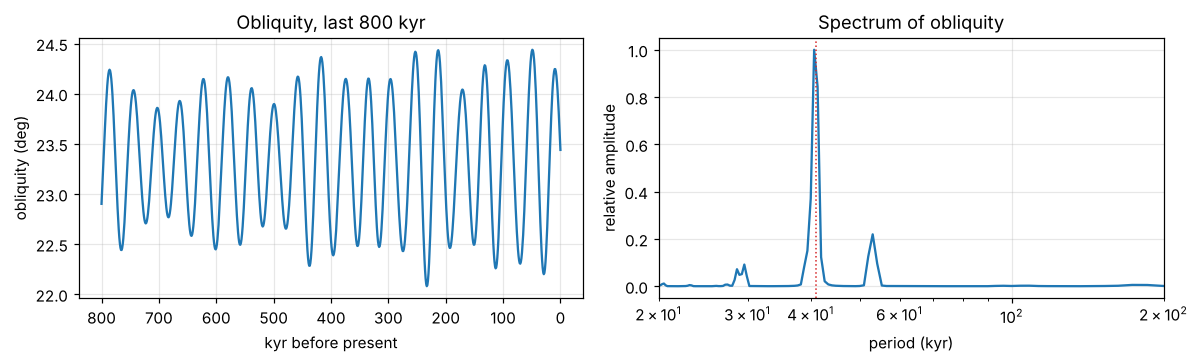

In [10]:
I0  = np.radians([7.005, 3.395, 0.0, 1.850, 1.303, 2.489, 0.773, 1.770])      # J2000 inclinations to the J2000 ecliptic
Om0 = np.radians([48.33, 76.68, 0.0, 49.56, 100.46, 113.67, 74.02, 131.78])   # J2000 nodes

def incl_matrix():
    n = ASEC_REV/a**1.5; N = len(a); B = np.zeros((N, N))
    for j in range(N):
        for k in range(N):
            if j == k: continue
            al, alb = (a[j]/a[k],)*2 if a[j] < a[k] else (a[k]/a[j], 1.0)
            c = 0.25*n[j]*m[k]/(1+m[j])*al*alb*laplace_b(1.5, 1, al)
            B[j, j] -= c; B[j, k] = c
    return B

B = incl_matrix()
s_modes, Vs = np.linalg.eig(B); s_modes, Vs = s_modes.real, Vs.real
cs = np.linalg.solve(Vs, np.sin(I0)*np.cos(Om0) + 1j*np.sin(I0)*np.sin(Om0))
rad = lambda x: np.radians(x/3600.0)                                        # arcsec/yr -> rad/yr

g_vals, V_g, c_g = secular(np.arange(8))                                    # eccentricity solution (Part B)
def z_earth(t):                                                             # e*exp(i*varpi) of Earth, t in yr (negative = past)
    return sum(V_g[2, i]*c_g[i]*np.exp(1j*rad(g_vals[i])*t) for i in range(8))
def normal(t):                                                              # orbit normal of Earth
    zt = sum(Vs[2, i]*cs[i]*np.exp(1j*rad(s_modes[i])*t) for i in range(8)); q, p = zt.real, zt.imag
    return np.array([p, -q, np.sqrt(1 - p*p - q*q)])

alpha = rad(50.4/np.cos(np.radians(23.439)))
def spin_rhs(t, s):
    nh = normal(t); return -alpha*(nh @ s)*np.cross(nh, s)
eps_0 = np.radians(23.439); s_init = np.array([0, np.sin(eps_0), np.cos(eps_0)])
T_BACK = -2.6e6
spin = solve_ivp(spin_rhs, (0, T_BACK), s_init, method="DOP853", rtol=1e-10, atol=1e-12, dense_output=True)
eps_of = lambda t: np.degrees(np.arccos(np.clip(spin.sol(t) @ normal(t), -1, 1)))

# checks
fwd = solve_ivp(spin_rhs, (0, 100.0), s_init, method="DOP853", rtol=1e-12, atol=1e-14, dense_output=True)
deps = (np.degrees(np.arccos(fwd.sol(100.0) @ normal(100.0))) - eps_of(0.0))*3600/100.0
tk_grid = np.arange(0, 2600.1, 1.0)                                         # kyr before present
eps_series = np.array([eps_of(-1e3*x) for x in tk_grid])
print(f"obliquity today {eps_of(0.0):.3f} deg;  d(eps)/dt today = {deps:.3f} arcsec/yr   (observed about -0.47)")
print(f"range over last 1 Myr: {eps_series[:1001].min():.2f} to {eps_series[:1001].max():.2f} deg")
print("p + s_i periods (kyr):", np.round(ASEC_REV/(50.4 + np.sort(s_modes))/1e3, 1)[:4])

sig = eps_series - eps_series.mean(); F = np.abs(np.fft.rfft(sig*np.hanning(len(sig)))); fr = np.fft.rfftfreq(len(sig), 1.0)
pk = sorted([i for i in range(2, len(F)-1) if F[i] > F[i-1] and F[i] > F[i+1] and F[i] > .1*F.max()], key=lambda i: -F[i])[:3]
print("spectral peaks of eps(t) (kyr):", [round(1/fr[i], 1) for i in pk])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(tk_grid[:801], eps_series[:801]); ax[0].invert_xaxis(); ax[0].set(xlabel="kyr before present", ylabel="obliquity (deg)", title="Obliquity, last 800 kyr")
ax[1].plot(1/fr[1:], F[1:]/F.max()); ax[1].set(xscale="log", xlim=(20, 200), xlabel="period (kyr)", ylabel="relative amplitude", title="Spectrum of obliquity")
ax[1].axvline(41, color="C3", ls=":", lw=1)
plt.tight_layout(); plt.show()

**Result.** The spin equation with a moving orbit normal gives $d\varepsilon/dt=-0.47''$/yr today, matching the observed rate, and an obliquity range of 22.1° to 24.4° over the last Myr. The spectrum has its main peak at 41 kyr (from $s_3$, with $s_4$ at 39.6 kyr as a close neighbour) and a second one near 53 kyr (from $s_1$).

### E.2 Daily insolation at 65°N
Milankovitch's argument is that summer insolation at high northern latitudes controls ice-sheet growth [8, 9]. For the daily-mean insolation at latitude $\varphi$ and true solar longitude $\lambda$ [6],

$$Q=\frac{S_0}{\pi}\frac{1}{\rho^2}\Big(h_0\sin\varphi\sin\delta+\cos\varphi\cos\delta\sin h_0\Big),\quad \sin\delta=\sin\varepsilon\sin\lambda,\quad \cos h_0=-\tan\varphi\tan\delta,$$

with $\rho=r/a=(1-e^2)/(1+e\cos\nu)$ and $\nu=\lambda-\varpi$. Here $\varpi$ is the longitude of perihelion of the Sun's apparent orbit measured from the **moving** vernal equinox, which is Earth's heliocentric $\varpi_\oplus$ (from Part B, measured from the fixed J2000 equinox) converted to the moving equinox, plus $180^\circ$. The vernal equinox direction is $\hat{\boldsymbol\gamma}\propto\hat{\mathbf s}\times\hat{\mathbf n}$. All three orbital parameters $(\varepsilon,e,\varpi)$ come from the code above. We take the summer solstice, $\lambda=90^\circ$, and $S_0=1361$ W/m².

Check at $t=0$: $\varpi=282.9^\circ$, so at the June solstice Earth is near aphelion ($\rho>1$).

The first-order errors in $g_5$ and $g_6$ shift the phase of the eccentricity and precession terms over hundreds of kyr, so the time series below are used for spectra, not for dating individual events.

t=0: Q = 477.9 W/m2, eps = 23.44 deg, e = 0.0167, varpi = 282.9 deg
Q(65N, solstice) range over 2.6 Myr: 432 to 561 W/m2


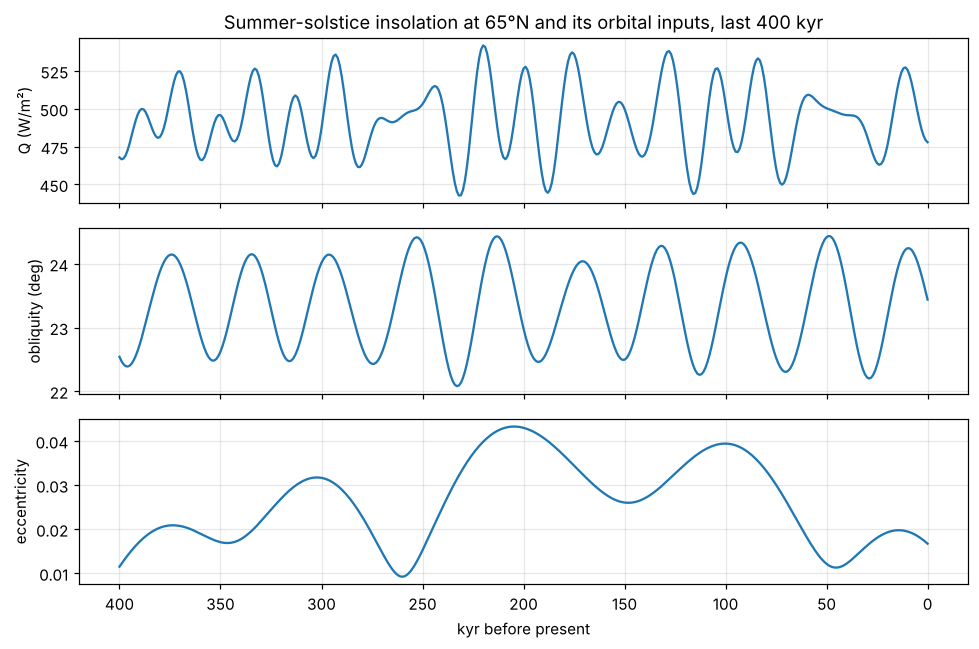

In [11]:
def insolation(t, lat=65.0, lam=np.pi/2, S0=1361.0):
    '''Daily-mean insolation (W/m2) at latitude lat (deg), solar longitude lam, time t (yr, negative = past). Returns Q, eps, e, varpi.'''
    phi = np.radians(lat); nh = normal(t); sv = spin.sol(t) if t != 0 else s_init
    sv = sv/np.linalg.norm(sv); ec = np.arccos(np.clip(nh @ sv, -1, 1))
    gam = np.cross(sv, nh); gam /= np.linalg.norm(gam)                      # vernal equinox direction
    perp = np.cross(nh, gam)
    z = z_earth(t); e = abs(z); vp = np.angle(z)
    P = np.array([np.cos(vp), np.sin(vp), 0.0]); P -= (P @ nh)*nh; P /= np.linalg.norm(P)
    varpi = (np.arctan2(P @ perp, P @ gam) + np.pi) % (2*np.pi)             # Berger convention
    nu = lam - varpi; rho = (1 - e*e)/(1 + e*np.cos(nu))
    dec = np.arcsin(np.sin(ec)*np.sin(lam))
    h0 = np.arccos(np.clip(-np.tan(phi)*np.tan(dec), -1, 1))
    Q = S0/np.pi/rho**2*(h0*np.sin(phi)*np.sin(dec) + np.cos(phi)*np.cos(dec)*np.sin(h0))
    return Q, np.degrees(ec), e, np.degrees(varpi)

Q0, e_0, ee0, vp0 = insolation(0.0)
print(f"t=0: Q = {Q0:.1f} W/m2, eps = {e_0:.2f} deg, e = {ee0:.4f}, varpi = {vp0:.1f} deg")

res = np.array([insolation(-1e3*x) for x in tk_grid])                      # columns: Q, eps, e, varpi
Qs, eps_s, e_s, varpi_s = res.T
print(f"Q(65N, solstice) range over 2.6 Myr: {Qs.min():.0f} to {Qs.max():.0f} W/m2")

fig, ax = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
sl = slice(0, 401)
ax[0].plot(tk_grid[sl], Qs[sl]);    ax[0].set_ylabel("Q (W/m²)")
ax[1].plot(tk_grid[sl], eps_s[sl]); ax[1].set_ylabel("obliquity (deg)")
ax[2].plot(tk_grid[sl], e_s[sl]);   ax[2].set_ylabel("eccentricity"); ax[2].set_xlabel("kyr before present"); ax[2].invert_xaxis()
ax[0].set_title("Summer-solstice insolation at 65°N and its orbital inputs, last 400 kyr")
plt.tight_layout(); plt.show()

### E.3 Comparison with the LR04 benthic δ¹⁸O stack
LR04 [10] is the average of 57 benthic δ¹⁸O records and measures global ice volume plus deep-ocean temperature (higher δ¹⁸O means more ice). Its age model was tuned to a simple ice model forced by 21 June insolation at 65°N [10], so the agreement at 23 and 41 kyr is partly built in, and a match in those bands says less than it appears to. Power at ~100 kyr is not an input of that tuning.

We compare the spectra of $Q$ and of LR04 in two windows: 0 to 1 Myr (the 100 kyr world) and 1.5 to 2.5 Myr (the 41 kyr world). Band fractions are the share of total variance after a linear detrend.

LR04 points: 2115  time span (kyr): 0.0 - 5320.0


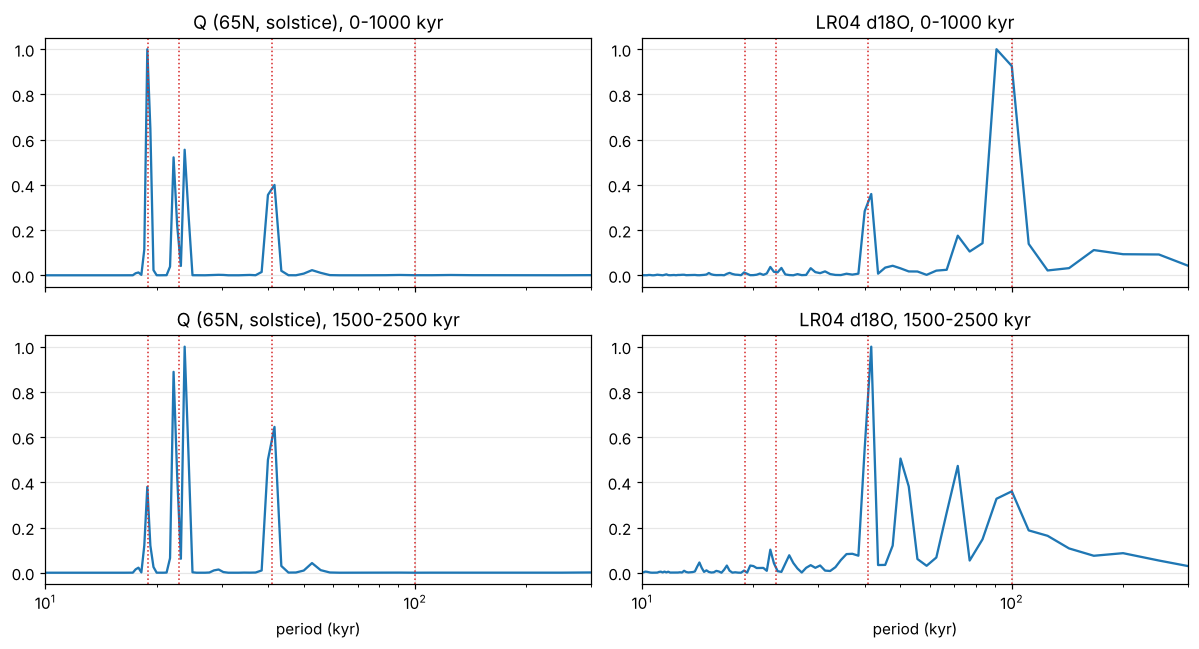

share of variance in band                precession 15-30   obliquity 35-48   80-130 kyr
  0-1000 kyr     Q                          0.80              0.18           0.001
  0-1000 kyr     LR04                       0.06              0.18           0.534
  1500-2500 kyr  Q                          0.74              0.24           0.000
  1500-2500 kyr  LR04                       0.10              0.31           0.183


In [12]:
import os, urllib.request
from scipy.signal import periodogram

def load_lr04(path="LR04stack.txt"):
    if not os.path.exists(path):
        url = "https://raw.githubusercontent.com/benmarwick/gsloid/master/data-raw/lisiecki2005.txt"    # NOAA NCEI file, first table
        raw = urllib.request.urlopen(url, timeout=60).read().decode("latin-1")
        rows = []
        for line in raw.splitlines():
            p = line.split()
            try: v = [float(x) for x in p] if len(p) == 3 else None
            except ValueError: v = None
            if v is not None:
                if rows and v[0] <= rows[-1][0]: break
                rows.append(v)
            elif rows: break
        np.savetxt(path, np.array(rows), fmt="%g", header="Time_kyr d18O_permil StdErr (LR04, Lisiecki & Raymo 2005)")
    return np.loadtxt(path)

lr = load_lr04(); d18 = np.interp(tk_grid, lr[:, 0], lr[:, 1])
print("LR04 points:", len(lr), " time span (kyr):", lr[0, 0], "-", lr[-1, 0])

def spec(x):
    f, P = periodogram(x - x.mean(), fs=1.0, window="hann", detrend="linear")        # fs in cycles/kyr
    return 1/f[1:], P[1:]
def band(x, lo, hi):
    per, P = spec(x); return P[(per >= lo) & (per <= hi)].sum()/P.sum()

windows = {"0-1000 kyr": (0, 1000), "1500-2500 kyr": (1500, 2500)}
fig, ax = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for r_i, (name, (a0, a1)) in enumerate(windows.items()):
    for c_i, (lab, x) in enumerate((("Q (65N, solstice)", Qs), ("LR04 d18O", d18))):
        per, P = spec(x[a0:a1+1]); ax[r_i, c_i].plot(per, P/P.max())
        ax[r_i, c_i].set(xscale="log", xlim=(10, 300), title=f"{lab}, {name}")
        for p in (19, 23, 41, 100): ax[r_i, c_i].axvline(p, color="C3", ls=":", lw=1)
for a_ in ax[1]: a_.set_xlabel("period (kyr)")
plt.tight_layout(); plt.show()

print("share of variance in band                precession 15-30   obliquity 35-48   80-130 kyr")
for name, (a0, a1) in windows.items():
    for lab, x in (("Q   ", Qs), ("LR04", d18)):
        xx = x[a0:a1+1]; print(f"  {name:14s} {lab}                     {band(xx,15,30):6.2f}            {band(xx,35,48):6.2f}          {band(xx,80,130):6.3f}")

**Result.** The insolation is almost entirely precession (15 to 30 kyr, ~80 % of variance) plus obliquity (~20 %), with essentially nothing at 80 to 130 kyr, even though the eccentricity itself has strong ~100 kyr terms (Part B). The 100 kyr eccentricity cycle modulates the *amplitude* of the precession term (the factor $e$ in $e\sin\varpi$) and does not appear as a frequency in $Q$. LR04 in the last Myr is the opposite: about half its variance sits at 80 to 130 kyr and only ~6 % in the precession band. Before ~1 Myr, LR04 has more obliquity power and the 100 kyr band shrinks. A linear response to $Q$ cannot reproduce either record.

### E.4 The 100 kyr problem
Annual-mean insolation depends on $e$ only through $1/\sqrt{1-e^2}$, a change of ~0.2 % for $e=0.06$, and $Q$ has no 100 kyr line (above). Yet the late-Pleistocene ice volume has its strongest power there, and the dominant period was 41 kyr before the mid-Pleistocene transition at about 1 Myr, with no change in orbital forcing. The explanations in the literature disagree, and none is settled:

| Position | Argument | Source |
|---|---|---|
| Obliquity pacing | Terminations occur at times of high obliquity, every second or third 41 kyr cycle; the 100 kyr scale is the average spacing. A statistical test rejects independence of terminations from obliquity at the 5 % level but not from eccentricity or precession. | Huybers & Wunsch 2005 [11], https://dash.harvard.edu/entities/publication/73120378-873e-6bd4-e053-0100007fdf3b |
| Orbital inclination | The 100 kyr cycle comes from the inclination of Earth's orbital plane, which has a 100 kyr period, not from eccentricity. The proposed climate link is accretion of dust or meteoroids, which is not an insolation effect. | Muller & MacDonald 1995, 1997 [12], https://muller.lbl.gov/papers/sciencespectra.htm |
| Internal nonlinear dynamics | Multiple equilibria of the climate system produce the timing of the glacial cycles within the framework of astronomical forcing. | Paillard 1998 [13], https://doi.org/10.1038/34891 |
| Review of open issues | Review of recent progress, noting that a complete theory of the ice ages is still elusive. | Raymo & Huybers 2008 [14], https://phuybers.sites.fas.harvard.edu/Doc/Raymo_Nature2008.pdf |

### E.5 Toy threshold model (illustration only)
Ice volume $v\in[0,1]$ grows at a constant rate. A termination starts when $v$ exceeds a minimum size $v_\text{min}$ and the normalised insolation $Q_n$ exceeds a threshold that falls as the ice sheet grows, $\theta_0-\theta_1 v$. Then $v$ collapses at a fast constant rate. The model is not fitted to LR04. Its spacing is largely set by the assumed fill time, so it shows how a threshold converts a 20 to 40 kyr forcing into a longer cycle, not that this is the cause.

0-1000 kyr     terminations:  9  spacing mean 104 kyr  (min 100, max 119)
1500-2500 kyr  terminations:  9  spacing mean 104 kyr  (min 100, max 110)


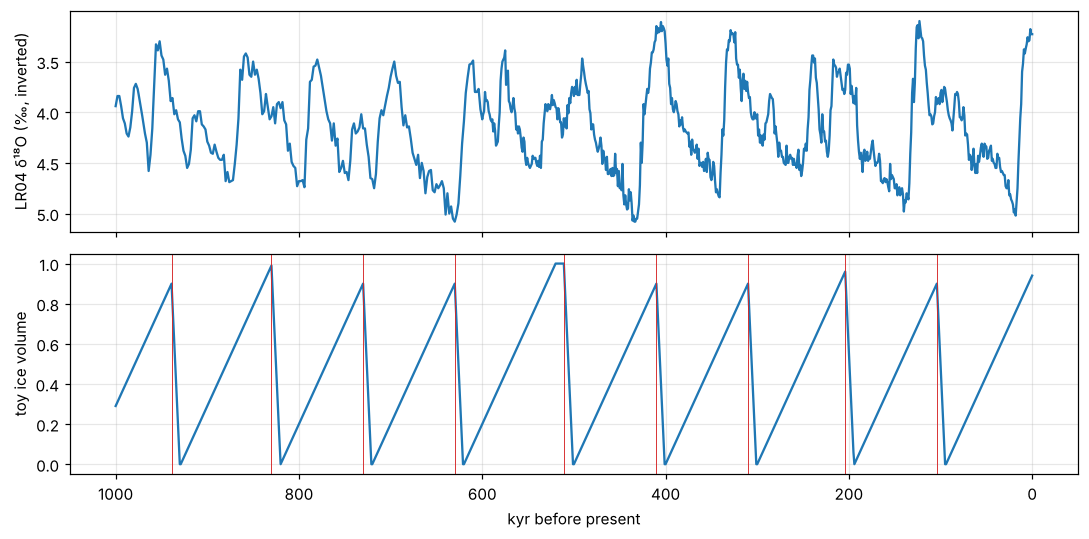

In [13]:
Qn = (Qs - Qs.mean())/Qs.std()
def toy(Qn, tk, r=1/100., rd=1/10., th0=1.0, th1=1.0, vmin=0.9):
    t = tk[::-1]; q = Qn[::-1]                                              # forward in time (kyr before present decreasing)
    v, state, out, term = 0.0, "grow", [], []
    for ti, qi in zip(t, q):
        if state == "grow":
            v = min(v + r, 1.0)
            if v >= vmin and qi > th0 - th1*v: state = "collapse"; term.append(ti)
        else:
            v -= rd
            if v <= 0: v, state = 0.0, "grow"
        out.append(v)
    return np.array(out)[::-1], np.array(term)

v_toy, term = toy(Qn, tk_grid)
for name, (a0, a1) in windows.items():
    tt = term[(term >= a0) & (term < a1)]
    print(f"{name:14s} terminations: {len(tt):2d}  spacing mean {(-np.diff(tt)).mean():.0f} kyr  (min {(-np.diff(tt)).min():.0f}, max {(-np.diff(tt)).max():.0f})")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(tk_grid[:1001], d18[:1001]); ax[0].invert_yaxis(); ax[0].set_ylabel("LR04 δ¹⁸O (‰, inverted)")
ax[1].plot(tk_grid[:1001], v_toy[:1001]); ax[1].set_ylabel("toy ice volume"); ax[1].set_xlabel("kyr before present"); ax[1].invert_xaxis()
for x in term[term < 1000]: ax[1].axvline(x, color="C3", lw=.6)
plt.tight_layout(); plt.show()

**Result.** With the minimum-size condition the toy model gives a sawtooth with a mean spacing near 100 kyr in the last Myr, and terminations occur at insolation maxima by construction. The same parameters give a similar ~100 kyr spacing in the 1.5 to 2.5 Myr window, where the record shows 41 kyr cycles, so the model does not reproduce the mid-Pleistocene transition. Reproducing it needs a time-dependent parameter (for example a slowly growing $v_\text{min}$), which would move the explanation into that parameter and leave the transition itself unexplained.

## References
1. Murray, C. D. & Dermott, S. F. (1999). *Solar System Dynamics*. Cambridge University Press, ch. 7 (secular perturbations, Laplace coefficients).
2. Fitzpatrick, R. *Celestial Mechanics* lecture notes, "Secular evolution of planetary orbits", Table 10.1. https://farside.ph.utexas.edu/teaching/celestial/Celestial/node91.html
3. Brouwer, D. & van Woerkom, A. J. J. (1950). The secular variations of the orbital elements of the principal planets. *Astronomical Papers of the American Ephemeris* 13, 81-107.
4. Laskar, J. et al. (2011). La2010: a new orbital solution for the long-term motion of the Earth. *Astronomy & Astrophysics* 532, A89 (Table 6, secular frequencies). https://www.aanda.org/articles/aa/full_html/2011/08/aa16836-11/T6.html
5. Alnajjarine, N., Mogavero, F. & Laskar, J. (2025). Numerical approach to second-order canonical perturbation theory in the planetary 3-body problem. arXiv:2506.13745 (errors of first-order theory in $g_5$, $g_6$).
6. Berger, A. L. (1978). Long-term variations of daily insolation and Quaternary climatic changes. *Journal of the Atmospheric Sciences* 35, 2362-2367.
7. Laskar, J. et al. (2004). A long-term numerical solution for the insolation quantities of the Earth. *Astronomy & Astrophysics* 428, 261-285.
8. Milankovitch, M. (1941). *Kanon der Erdbestrahlung und seine Anwendung auf das Eiszeitenproblem*. Royal Serbian Academy, Belgrade.
9. Hays, J. D., Imbrie, J. & Shackleton, N. J. (1976). Variations in the Earth's orbit: pacemaker of the ice ages. *Science* 194, 1121-1132.
10. Lisiecki, L. E. & Raymo, M. E. (2005). A Pliocene-Pleistocene stack of 57 globally distributed benthic δ¹⁸O records. *Paleoceanography* 20, PA1003, doi:10.1029/2004PA001071. Data: NOAA NCEI, https://doi.org/10.25921/K88J-0106
11. Huybers, P. & Wunsch, C. (2005). Obliquity pacing of the late Pleistocene glacial terminations. *Nature* 434, 491-494, doi:10.1038/nature03401.
12. Muller, R. A. & MacDonald, G. J. (1995). Glacial cycles and orbital inclination. *Nature* 377, 107-108; (1997). Glacial cycles and astronomical forcing. *Science* 277, 215-218, doi:10.1126/science.277.5323.215.
13. Paillard, D. (1998). The timing of Pleistocene glaciations from a simple multiple-state climate model. *Nature* 391, 378-381, doi:10.1038/34891.
14. Raymo, M. E. & Huybers, P. (2008). Unlocking the mysteries of the ice ages. *Nature* 451, 284-285, doi:10.1038/nature06589.